# trPL simulation

In [7]:
import os, sys
try:
    import pySIMsalabim as sim
except ImportError: # add parent directory to sys.path if pySIMsalabim is not installed
    sys.path.append('..')
    import pySIMsalabim as sim
from pySIMsalabim.experiments.trPL import *

# Use the default input files shipped with the pySIMsalabim tests (pySIMsalabim/tests/sim_inputs/default):
# check that they match the SIMsalabim version and copy them into SIMsalabim/SimSS and SIMsalabim/ZimT
sys.path.append(os.path.join('..', 'pySIMsalabim', 'tests'))
from sim_inputs_setup import prepare_test_inputs, cleanup_test_inputs
prepare_test_inputs(convert=False)

Test inputs for SimSS: version matches SIMsalabim 5.37
Test inputs for ZimT: version matches SIMsalabim 5.37
Copying the SimSS test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/SimSS
Copying the ZimT test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/ZimT


### Setup the simulation

In [8]:
# Set the path to the simulation setup file
cwd = os.path.abspath('..')
session_path = os.path.join(cwd, 'SIMsalabim','ZimT')
zimt_device_parameters = os.path.join(session_path, 'simulation_setup_trPL_test.txt')

# Set the trPL simulation parameters
lyr_idx = 1
t_max = 1E-7
t_step = 1E-9
t_pulse = 10E-9
t_scale = 'log'
FWHM = 3E-9
ret, mess = run_trPL_simu(zimt_device_parameters, session_path, lyr_idx, t_max, t_scale, t_step, t_pulse, FWHM, output_file = 'trPL.dat', tj_name = 'tj.dat')


### Plot results

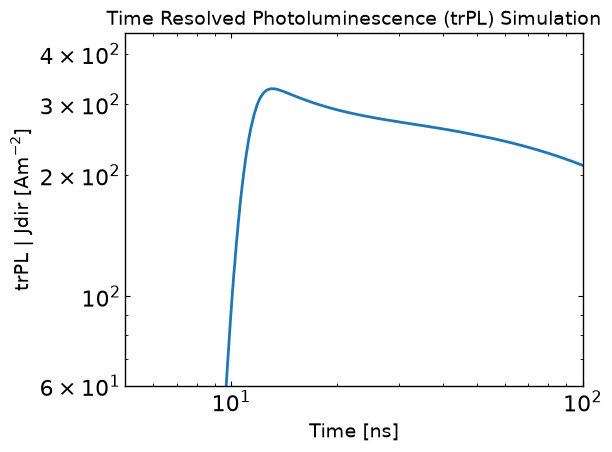

In [11]:
plot_trPL(session_path, output_file = 'trPL.dat', xlim = [5E-9,1E-7], ylim = [60,450])


In [12]:
# Clean up the output files (comment out if you want to keep the output files)
sim.clean_all_output(session_path)
sim.clean_up_output('trPL',session_path)
sim.delete_folders('tmp',session_path)

# Remove the test input files copied into the SIMsalabim folder
cleanup_test_inputs()